In [ ]:
%%writefile study_sessions.csv
day,topic,minutes,exercises_completed,confidence_score,study_method
Monday,OOP,50,4,7,Video
Tuesday,CSV files,65,5,6,Practice
Wednesday,Matplotlib,45,3,not recorded,Video
Thursday,OOP,70,6,8,Practice
Friday,Exceptions,40,4,7,Reading
Saturday,Matplotlib,80,7,9,Practice

Overwriting study_sessions.csv


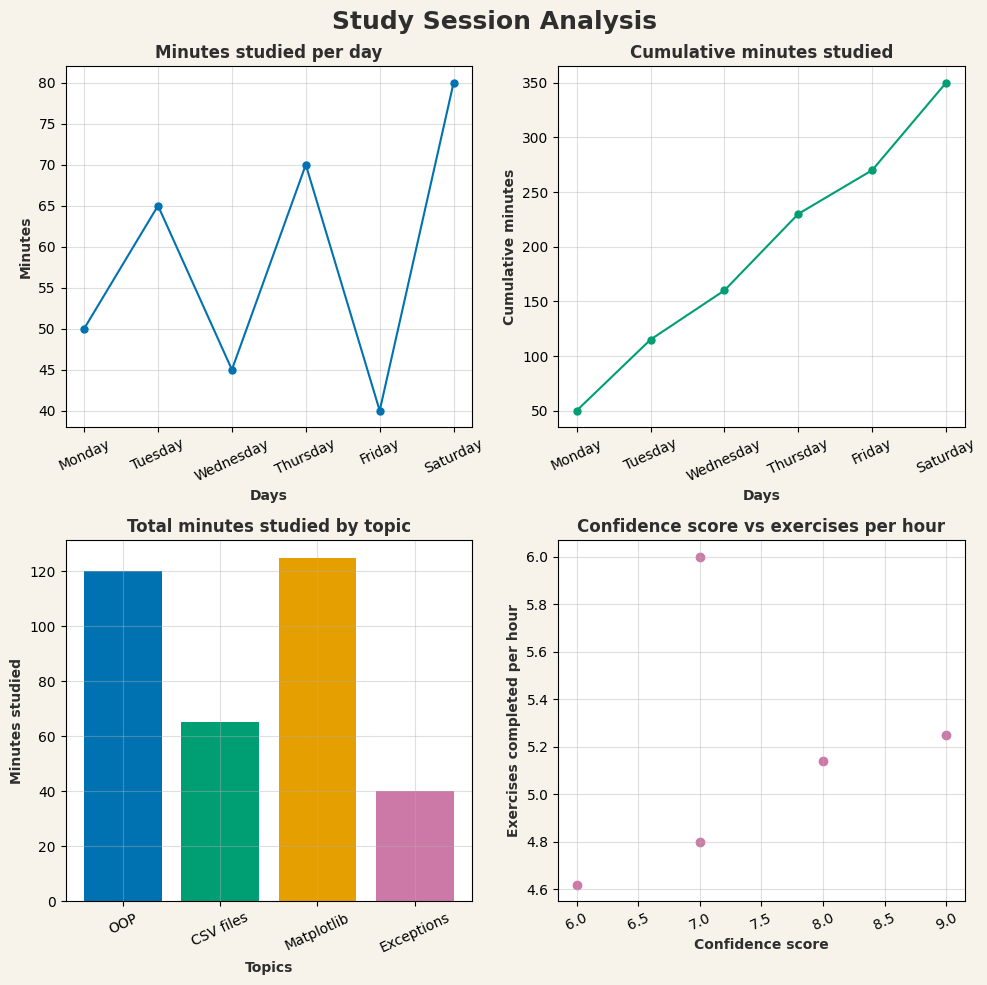

Study Session Progress Tracker

350 minutes studied, exceeding the goal by 50 minutes.
Number of sessions: 6
Missing confidence scores: 1
OOP: 120 minutes
CSV files: 65 minutes
Matplotlib: 125 minutes
Exceptions: 40 minutes



In [ ]:
import csv

import matplotlib.pyplot as plt

class StudySession:
    """Represents one study session."""
    def __init__(self, day, topic, minutes, exercises_completed, confidence_score, study_method):
        """Initialises a new study session object."""
        self.day = day
        self.topic = topic
        self.minutes = minutes
        self.exercises_completed = exercises_completed
        self.confidence_score = confidence_score
        self.study_method = study_method

    def exercises_per_hour(self):
        """Calculates exercises completed per hour."""
        session_hours = self.minutes / 60
        exercises_per_hour = self.exercises_completed / session_hours
        return exercises_per_hour


study_sessions = []

try:
    with open("study_sessions.csv", "r") as study_sessions_data:
        study_sessions_csv = csv.DictReader(study_sessions_data)

        for study_session in study_sessions_csv:
            day = study_session["day"]
            topic = study_session["topic"]
            minutes = int(study_session["minutes"])
            exercises_completed = int(study_session["exercises_completed"])

            if study_session["confidence_score"] == "not recorded":
                confidence_score = None
            else:
                confidence_score = int(study_session["confidence_score"])

            study_method = study_session["study_method"]

            current_study_session = StudySession(day, topic, minutes, exercises_completed, confidence_score, study_method)
            study_sessions.append(current_study_session)

except FileNotFoundError as error:
        print(f"Error: {error}")

except ValueError as error:
        print(f"Error: {error}")

else:
        days = []
        minutes = []
        exercises_completed = []
        exercises_per_hour = []
        cumulative_study_minutes = []
        running_minutes = 0
        missing_confidence_counter = 0

        for session in study_sessions:
            days.append(session.day)
            minutes.append(session.minutes)
            exercises_completed.append(session.exercises_completed)
            exercises_per_hour.append(round(session.exercises_per_hour(), 2))
            running_minutes += session.minutes
            cumulative_study_minutes.append(running_minutes)

            if session.confidence_score is None:
                missing_confidence_counter += 1


        confidence_scores = []
        exercises_per_hour_values = []

        for session in study_sessions:
            if session.confidence_score is not None:
                confidence_scores.append(session.confidence_score)
                exercises_per_hour_values.append(round(session.exercises_per_hour(), 2))


        minutes_by_topic = {}

        for session in study_sessions:
            if session.topic in minutes_by_topic:
                minutes_by_topic[session.topic] += session.minutes
            else:
                minutes_by_topic[session.topic] = session.minutes


        topic_names = []
        minute_totals = []

        for topic in minutes_by_topic:
            topic_names.append(topic)
            minute_totals.append(minutes_by_topic[topic])


        session_minutes_by_study_method = {}

        for session in study_sessions:
            if session.study_method in session_minutes_by_study_method:
                session_minutes_by_study_method[session.study_method] += session.minutes
            else:
                session_minutes_by_study_method[session.study_method] = session.minutes


        method_names = []
        minutes_by_method = []

        for method in session_minutes_by_study_method:
            method_names.append(method)
            minutes_by_method.append(session_minutes_by_study_method[method])


        daily_color = "#0072B2"
        cumulative_color = "#009E73"
        scatter_color = "#CC79A7"
        bar_colors = ["#0072B2", "#009E73", "#E69F00", "#CC79A7"]
        grid_color = "#D9E2E8"
        warm_cream = "#F7F3EA"
        charcoal = "#2E2E2E"

        fig, axes = plt.subplots(2, 2, figsize=(10, 10))

        fig.patch.set_facecolor(warm_cream)

        plt.suptitle("Study Session Analysis", color=charcoal, fontsize=18, fontweight="bold")

        axes[0, 0].plot(days, minutes, color=daily_color, marker="o", markersize=5)
        axes[0, 0].set_title("Minutes studied per day")
        axes[0, 0].set_xlabel("Days")
        axes[0, 0].set_ylabel("Minutes")
        axes[0, 0].tick_params(axis="x", rotation=25)
        axes[0, 0].grid(alpha=0.4)

        axes[0, 1].plot(days, cumulative_study_minutes, color=cumulative_color, marker="o", markersize=5)
        axes[0, 1].set_title("Cumulative minutes studied")
        axes[0, 1].set_xlabel("Days")
        axes[0, 1].set_ylabel("Cumulative minutes")
        axes[0, 1].tick_params(axis="x", rotation=25)
        axes[0, 1].grid(alpha=0.4)

        axes[1, 0].bar(topic_names, minute_totals, color=bar_colors)
        axes[1, 0].set_title("Total minutes studied by topic")
        axes[1, 0].set_xlabel("Topics")
        axes[1, 0].set_ylabel("Minutes studied")
        axes[1, 0].tick_params(axis="x", rotation=25)
        axes[1, 0].grid(alpha=0.4)

        axes[1, 1].scatter(
            confidence_scores,
            exercises_per_hour_values,
            color=scatter_color
        )
        axes[1, 1].set_title("Confidence score vs exercises per hour")
        axes[1, 1].set_xlabel("Confidence score")
        axes[1, 1].set_ylabel("Exercises completed per hour")
        axes[1, 1].tick_params(axis="x", rotation=25)
        axes[1, 1].grid(alpha=0.4)

        for ax in axes.flat:
            text_elements = [ax.title, ax.xaxis.label, ax.yaxis.label]

            for text in text_elements:
                text.set_color(charcoal)
                text.set_fontweight("bold")

        plt.tight_layout()
        plt.savefig("study_session_analysis.png")
        plt.show()


        study_goal = 300
        challenge_name = "Study Session Progress Tracker"

        if running_minutes > study_goal:
            goal_message = f"{running_minutes} minutes studied, exceeding the goal by {running_minutes - study_goal} minutes."
        elif running_minutes == study_goal:
            goal_message = f"{running_minutes} minutes studied, meeting the goal of {study_goal} exactly."
        else:
            goal_message = f"{running_minutes} minutes studied, missing the goal by {study_goal - running_minutes} minutes."


        with open("study_session_report.txt", "w") as summary_file:
            summary_file.write(f"{challenge_name}\n\n")
            summary_file.write(f"{goal_message}\n")
            summary_file.write(f"Number of sessions: {len(study_sessions)}\n")
            summary_file.write(f"Missing confidence scores: {missing_confidence_counter}\n")
            for topic in minutes_by_topic:
                summary_file.write(f"{topic}: {minutes_by_topic[topic]} minutes\n")


        with open("study_session_report.txt", "r") as summary_file:
            print(summary_file.read())

### What I found
I logged 350 minutes across six study sessions, 50 minutes over my goal. Matplotlib took up the most time at 125 minutes, with object-oriented programming only five minutes behind.